# Punto 2 · Generación de imágenes con difusión: **Oxford Flowers 102**
### Réplica del ejercicio del capítulo 17 de *Deep Learning with Python, 3.ª ed.* (F. Chollet & M. Watson)

**Universidad Autónoma de Occidente** · Inteligencia Artificial Generativa · Ingeniería de Datos e IA
Profesores: Jesús Alfonso López – José Luis Paniagua

Fuente: https://deeplearningwithpython.io/chapters/chapter17_image-generation/

En este notebook replicamos el modelo de difusión del libro, que aprende a generar **flores a color de 128×128** a partir de las ~8.000 fotos del conjunto *Oxford Flowers 102*. Primero va la réplica fiel del código del libro (sección por sección, comentada) y al final agregamos algunos experimentos para entender mejor qué está pasando: el proceso directo, el efecto del número de pasos, el proceso inverso paso a paso, la interpolación en el espacio de ruido y una métrica de calidad (KID).

### ¿En qué se diferencia del modelo de la clase (DDPM)?
| | Modelo de clase (DDPM, Géron) | Modelo del libro (Chollet) |
|---|---|---|
| Tiempo | discreto, $t\in\{1,\dots,T\}$, $T=4000$ | **continuo**, $t\in[0,1]$ |
| Programación de ruido | coseno sobre $\bar\alpha_t$ | **coseno por ángulos**: `signal_rate = cos(θ)`, `noise_rate = sin(θ)` |
| Cómo recibe el tiempo la red | codificación sinusoidal + `Dense` sumada a cada bloque | se le pasa directamente el **noise rate** (varianza), expandido a toda la imagen y concatenado |
| Muestreo | DDPM estocástico, T pasos | **DDIM determinista**, ~20 pasos |
| Pérdida | Huber | MAE (error absoluto medio) |
| Pesos para generar | crudos | **EMA** integrada en el optimizador (`use_ema=True`) |

> ⚙️ **Entorno de ejecución → Cambiar tipo de entorno → GPU (T4 o mejor)**. Con 100 épocas el entrenamiento tarda aprox. 1 hora en una T4.

## 0. Instalación y configuración
El libro usa **Keras 3**, que puede correr sobre JAX, TensorFlow o PyTorch. Usamos TensorFlow como *backend* porque viene instalado en Colab y en la mayoría de equipos (el libro también funciona con JAX o PyTorch); la línea de `KERAS_BACKEND` debe ir **antes** de importar Keras.

In [2]:
# Solo en Colab: actualiza Keras 3 (en un equipo local no hace falta correr esta celda)
import sys
if "google.colab" in sys.modules:
    !pip install keras --upgrade -q

In [3]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"   # también funciona con "jax" o "torch" si están instalados

import time
import numpy as np
import keras
from keras import layers, ops
from matplotlib import pyplot as plt

print("Keras:", keras.__version__, "| backend:", keras.config.backend())

Keras: 3.12.1 | backend: tensorflow


## 1. Descarga y preparación del conjunto de datos
Oxford Flowers 102 tiene 8.189 fotos de flores de 102 especies. No usamos las etiquetas: solo queremos aprender la distribución de las imágenes. Las redimensionamos a 128×128 **recortando** para conservar la proporción (si no, las flores saldrían estiradas).

In [4]:
fpath = keras.utils.get_file(
    origin="https://www.robots.ox.ac.uk/~vgg/data/flowers/102/102flowers.tgz",
    extract=True,
)

# Según la versión de Keras, get_file devuelve la carpeta extraída o el archivo;
# buscamos la carpeta 'jpg' que contiene las imágenes.
images_dir = os.path.join(fpath, "jpg")
if not os.path.isdir(images_dir):
    for root, dirs, files in os.walk(os.path.dirname(fpath)):
        if os.path.basename(root) == "jpg":
            images_dir = root
            break
print("Imágenes en:", images_dir, "| total:", len(os.listdir(images_dir)))

344862509/344862509 ━━━━━━━━━━━━━━━━━━━━ 10792s 31us/step
Imágenes en: C:\Users\Acer\.keras\datasets\102flowers.tgz\jpg | total: 8189


In [5]:
batch_size = 32
image_size = 128

dataset = keras.utils.image_dataset_from_directory(
    images_dir,
    labels=None,                  # no necesitamos etiquetas, solo las imágenes
    image_size=(image_size, image_size),
    crop_to_aspect_ratio=True,    # recorta en vez de deformar al redimensionar
)
# Todos los lotes del mismo tamaño: descartamos el último lote incompleto
dataset = dataset.rebatch(batch_size, drop_remainder=True)

Found 8189 files.


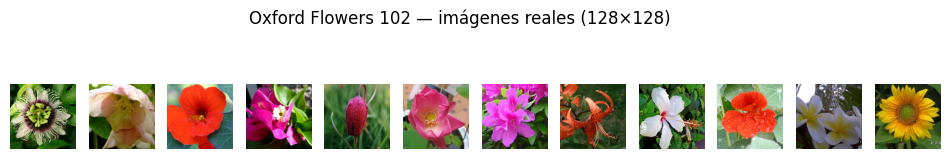

In [6]:
# Miramos algunas flores reales
for batch in dataset:
    imgs = batch.numpy()[:12]
    break

plt.figure(figsize=(12, 2.2))
for i, img in enumerate(imgs):
    plt.subplot(1, 12, i + 1); plt.imshow(img.astype("uint8")); plt.axis("off")
plt.suptitle("Oxford Flowers 102 — imágenes reales (128×128)"); plt.show()

## 2. El modelo de eliminación de ruido: una U-Net

La red recibe dos entradas: la **imagen ruidosa** y la **tasa de ruido** (cuánto ruido tiene). Devuelve una predicción del **ruido** contenido en la imagen.

- **Bloque residual:** `BatchNormalization` (sin parámetros de escala/desplazamiento) → `Conv2D` 3×3 con activación *swish* → `Conv2D` 3×3, más una conexión residual (con una conv 1×1 si cambia el número de canales).
- **Bajada:** por cada ancho en `widths[:-1]` aplicamos `block_depth` bloques residuales, guardamos cada salida para los saltos y reducimos la resolución con `AveragePooling2D` (128→64→32→16).
- **Centro:** bloques residuales con el ancho máximo.
- **Subida:** `UpSampling2D` bilineal y, antes de cada bloque, concatenamos la salida guardada correspondiente (las conexiones de salto de la U-Net).
- **Condicionamiento:** la tasa de ruido (un escalar por imagen) se **repite en todos los píxeles** con `UpSampling2D(image_size)` y se concatena como un canal más.
- La última capa se inicializa en **ceros**: antes de entrenar la red asume “no hay ruido”, lo que estabiliza el arranque.

In [7]:
def residual_block(x, width):
    # Bloque de capas con conexión residual
    input_width = x.shape[3]
    if input_width == width:
        residual = x
    else:
        residual = layers.Conv2D(width, 1)(x)       # ajusta canales para poder sumar
    x = layers.BatchNormalization(center=False, scale=False)(x)
    x = layers.Conv2D(width, 3, padding="same", activation="swish")(x)
    x = layers.Conv2D(width, 3, padding="same")(x)
    x = x + residual
    return x


def get_model(image_size, widths, block_depth):
    noisy_images = keras.Input(shape=(image_size, image_size, 3))
    noise_rates = keras.Input(shape=(1, 1, 1))

    x = layers.Conv2D(widths[0], 1)(noisy_images)
    # La tasa de ruido (1x1) se repite en toda la imagen y se concatena como un canal
    n = layers.UpSampling2D(image_size, interpolation="nearest")(noise_rates)
    x = layers.Concatenate()([x, n])

    skips = []
    # Etapa de bajada (downsampling)
    for width in widths[:-1]:
        for _ in range(block_depth):
            x = residual_block(x, width)
            skips.append(x)
        x = layers.AveragePooling2D(pool_size=2)(x)

    # Etapa central
    for _ in range(block_depth):
        x = residual_block(x, widths[-1])

    # Etapa de subida (upsampling) con conexiones de salto
    for width in reversed(widths[:-1]):
        x = layers.UpSampling2D(size=2, interpolation="bilinear")(x)
        for _ in range(block_depth):
            x = layers.Concatenate()([x, skips.pop()])
            x = residual_block(x, width)

    # Inicialización en ceros: al principio la red predice "no hay ruido"
    pred_noise_masks = layers.Conv2D(3, 1, kernel_initializer="zeros")(x)

    return keras.Model([noisy_images, noise_rates], pred_noise_masks)

## 3. La programación de difusión (*diffusion schedule*)

En vez de pasos discretos, el libro usa un **tiempo continuo** $t\in[0,1]$. A cada tiempo le corresponde un ángulo $\theta(t)$ que va linealmente entre $\arccos(0.95)$ y $\arccos(0.02)$, y:

$$\text{signal\_rate}=\cos\theta,\qquad \text{noise\_rate}=\sin\theta,\qquad x_t=\text{signal\_rate}\cdot x_0+\text{noise\_rate}\cdot\varepsilon$$

Como $\cos^2+\sin^2=1$, la varianza total se conserva (es una difusión de *varianza preservada*, igual que DDPM). Con $t=0$ queda 95 % de señal y con $t=1$ solo 2 %: nunca es 100 % ruido ni 100 % imagen, lo que evita divisiones por cero al reconstruir.

In [8]:
def diffusion_schedule(diffusion_times, min_signal_rate=0.02, max_signal_rate=0.95):
    start_angle = ops.cast(ops.arccos(max_signal_rate), "float32")
    end_angle = ops.cast(ops.arccos(min_signal_rate), "float32")
    diffusion_angles = start_angle + diffusion_times * (end_angle - start_angle)
    signal_rates = ops.cos(diffusion_angles)
    noise_rates = ops.sin(diffusion_angles)
    return noise_rates, signal_rates

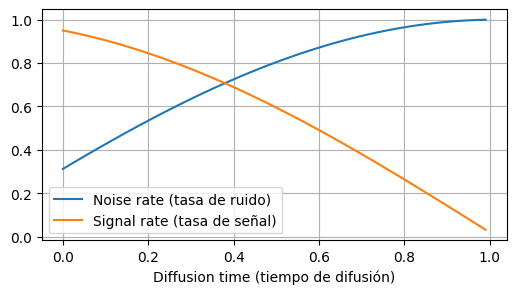

In [9]:
diffusion_times = ops.arange(0.0, 1.0, 0.01)
noise_rates, signal_rates = diffusion_schedule(diffusion_times)

# Conversión a NumPy (necesaria sobre todo con PyTorch)
diffusion_times = ops.convert_to_numpy(diffusion_times)
noise_rates = ops.convert_to_numpy(noise_rates)
signal_rates = ops.convert_to_numpy(signal_rates)

plt.figure(figsize=(6, 3))
plt.plot(diffusion_times, noise_rates, label="Noise rate (tasa de ruido)")
plt.plot(diffusion_times, signal_rates, label="Signal rate (tasa de señal)")
plt.xlabel("Diffusion time (tiempo de difusión)"); plt.legend(); plt.grid(True)
plt.show()

Veamos el **proceso directo** sobre una flor real: así se ve la entrada de la red a distintos tiempos de difusión.

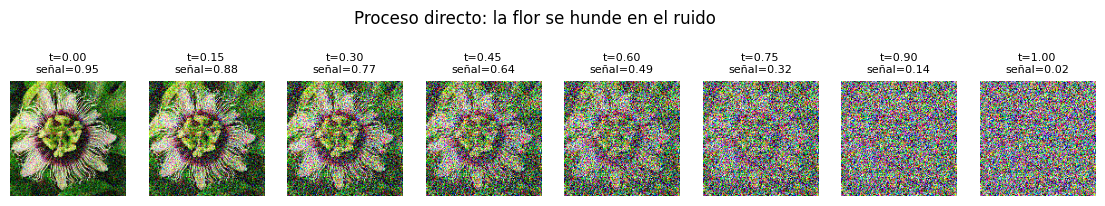

In [10]:
x0 = imgs[0:1] / 127.5 - 1.0                      # sólo para visualizar: escala a [-1, 1]
eps = np.random.randn(*x0.shape).astype("float32")
times = [0.0, 0.15, 0.3, 0.45, 0.6, 0.75, 0.9, 1.0]
plt.figure(figsize=(14, 2.2))
for i, t in enumerate(times):
    nr, sr = diffusion_schedule(ops.convert_to_tensor([[[[t]]]], dtype="float32"))
    xt = ops.convert_to_numpy(sr * x0 + nr * eps)[0]
    plt.subplot(1, len(times), i + 1)
    plt.imshow(np.clip((xt + 1) / 2, 0, 1)); plt.axis("off")
    plt.title(f"t={t:.2f}\nseñal={float(ops.convert_to_numpy(sr).ravel()[0]):.2f}", fontsize=8)
plt.suptitle("Proceso directo: la flor se hunde en el ruido", y=1.08); plt.show()

## 4. El modelo de difusión completo

La clase `DiffusionModel` envuelve la U-Net y define:

- `denoise`: llama a la U-Net para predecir el ruido y, con él, **reconstruye la imagen limpia** despejando $x_0=(x_t-\text{noise\_rate}\cdot\hat\varepsilon)/\text{signal\_rate}$.
- `call` (entrenamiento): normaliza las imágenes, toma ruido y tiempos aleatorios, ensucia las imágenes y pide a la red que prediga el ruido.
- `compute_loss`: error absoluto medio (MAE) entre el ruido real y el predicho.
- `generate`: parte de ruido puro y, durante `diffusion_steps` pasos, estima la imagen limpia y la **vuelve a ensuciar con un nivel de ruido un poco menor** (muestreo tipo DDIM, determinista). Al final desnormaliza a [0, 255].

In [11]:
class DiffusionModel(keras.Model):
    def __init__(self, image_size, widths, block_depth, **kwargs):
        super().__init__(**kwargs)
        self.image_size = image_size
        self.denoising_model = get_model(image_size, widths, block_depth)
        self.seed_generator = keras.random.SeedGenerator()
        self.loss = keras.losses.MeanAbsoluteError()   # nuestra función de pérdida
        self.normalizer = keras.layers.Normalization()  # para normalizar las imágenes de entrada

    def denoise(self, noisy_images, noise_rates, signal_rates):
        # La U-Net predice el ruido...
        pred_noise_masks = self.denoising_model([noisy_images, noise_rates])
        # ...y con él reconstruimos la imagen limpia predicha
        pred_images = (noisy_images - noise_rates * pred_noise_masks) / signal_rates
        return pred_images, pred_noise_masks

    def call(self, images):
        images = self.normalizer(images)
        # Ruido aleatorio
        noise_masks = keras.random.normal(
            (batch_size, self.image_size, self.image_size, 3), seed=self.seed_generator)
        # Tiempos de difusión aleatorios, uno por imagen
        diffusion_times = keras.random.uniform(
            (batch_size, 1, 1, 1), minval=0.0, maxval=1.0, seed=self.seed_generator)
        noise_rates, signal_rates = diffusion_schedule(diffusion_times)
        # Ensuciamos las imágenes
        noisy_images = signal_rates * images + noise_rates * noise_masks
        # Y les quitamos el ruido
        pred_images, pred_noise_masks = self.denoise(noisy_images, noise_rates, signal_rates)
        return pred_images, pred_noise_masks, noise_masks

    def compute_loss(self, x, y, y_pred, sample_weight=None, training=True):
        _, pred_noise_masks, noise_masks = y_pred
        return self.loss(noise_masks, pred_noise_masks)

    def generate(self, num_images, diffusion_steps):
        # Partimos de ruido puro
        noisy_images = keras.random.normal(
            (num_images, self.image_size, self.image_size, 3), seed=self.seed_generator)
        step_size = 1.0 / diffusion_steps
        for step in range(diffusion_steps):
            # Tasas de ruido y señal del paso actual
            diffusion_times = ops.ones((num_images, 1, 1, 1)) - step * step_size
            noise_rates, signal_rates = diffusion_schedule(diffusion_times)
            # Llamamos al modelo de eliminación de ruido
            pred_images, pred_noises = self.denoise(noisy_images, noise_rates, signal_rates)
            # Preparamos la imagen ruidosa para la siguiente iteración (menos ruido)
            next_diffusion_times = diffusion_times - step_size
            next_noise_rates, next_signal_rates = diffusion_schedule(next_diffusion_times)
            noisy_images = next_signal_rates * pred_images + next_noise_rates * pred_noises
        # Desnormalizamos para volver a valores entre 0 y 255
        images = self.normalizer.mean + pred_images * self.normalizer.variance ** 0.5
        return ops.clip(images, 0.0, 255.0)

### Callback de visualización
Al final de algunas épocas generamos 18 flores para ir viendo cómo mejora el modelo. (El libro lo hace en cada época; aquí lo hacemos cada `every` épocas para que la salida del notebook no sea gigante.)

In [12]:
class VisualizationCallback(keras.callbacks.Callback):
    def __init__(self, diffusion_steps=20, num_rows=3, num_cols=6, every=10):
        self.diffusion_steps = diffusion_steps
        self.num_rows = num_rows
        self.num_cols = num_cols
        self.every = every

    def on_epoch_end(self, epoch=None, logs=None):
        if (epoch + 1) % self.every != 0 and epoch != 0:
            return
        generated_images = self.model.generate(
            num_images=self.num_rows * self.num_cols,
            diffusion_steps=self.diffusion_steps,
        )
        plt.figure(figsize=(self.num_cols * 2.0, self.num_rows * 2.0))
        for row in range(self.num_rows):
            for col in range(self.num_cols):
                i = row * self.num_cols + col
                plt.subplot(self.num_rows, self.num_cols, i + 1)
                img = ops.convert_to_numpy(generated_images[i]).astype("uint8")
                plt.imshow(img)
                plt.axis("off")
        plt.suptitle(f"Época {epoch + 1}")
        plt.tight_layout()
        plt.show()
        plt.close()

## 5. Entrenamiento

Igual que en el libro:
- U-Net con anchos `[32, 64, 96, 128]` y 2 bloques residuales por nivel.
- El `Normalization` se ajusta (`adapt`) al conjunto de datos para conocer media y varianza por canal. **¡No olvidarlo!**
- Optimizador **AdamW** con decaimiento de la tasa de aprendizaje (`InverseTimeDecay`) y **promedio de Polyak / EMA** (`use_ema=True`): cada 100 pasos los pesos se reemplazan por su promedio móvil exponencial, lo que da muestras más limpias.
- 100 épocas.

In [13]:
model = DiffusionModel(image_size, widths=[32, 64, 96, 128], block_depth=2)
# Calcula la media y la varianza para normalizar (¡no olvidarlo!)
model.normalizer.adapt(dataset)

model.compile(
    optimizer=keras.optimizers.AdamW(
        learning_rate=keras.optimizers.schedules.InverseTimeDecay(
            initial_learning_rate=1e-3,
            decay_steps=1000,
            decay_rate=0.1,
        ),
        use_ema=True,               # promedio de Polyak (EMA) de los pesos
        ema_overwrite_frequency=100, # cada cuántos pasos se reemplazan los pesos por su EMA
    ),
)
print(f"Parámetros de la U-Net: {model.denoising_model.count_params():,}")

Parámetros de la U-Net: 1,943,525


Epoch 1/100
    255/Unknown 1212s 5s/step - loss: 0.5469

c:\Users\Acer\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


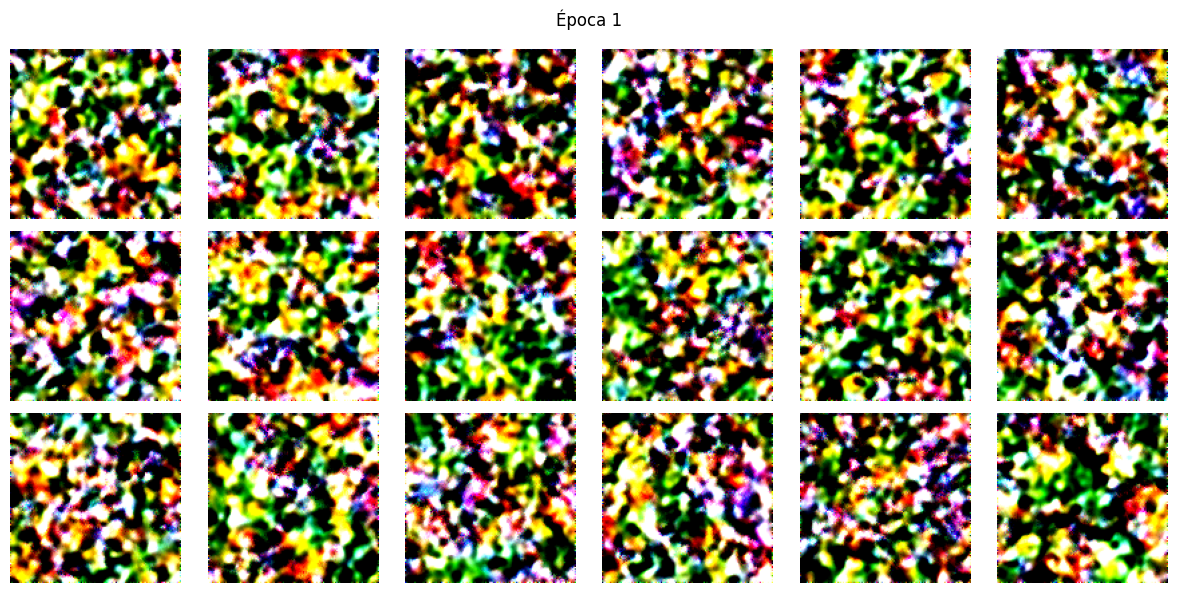

255/255 ━━━━━━━━━━━━━━━━━━━━ 1232s 5s/step - loss: 0.6116
Epoch 2/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1220s 5s/step - loss: 0.2144
Epoch 3/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1205s 5s/step - loss: 0.1952
Epoch 4/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1216s 5s/step - loss: 0.1873
Epoch 5/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1227s 5s/step - loss: 0.1823
Epoch 6/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1649s 6s/step - loss: 0.1757
Epoch 7/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 13595s 53s/step - loss: 0.1730
Epoch 8/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1254s 5s/step - loss: 0.1697
Epoch 9/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1229s 5s/step - loss: 0.1652
Epoch 10/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - loss: 0.1681

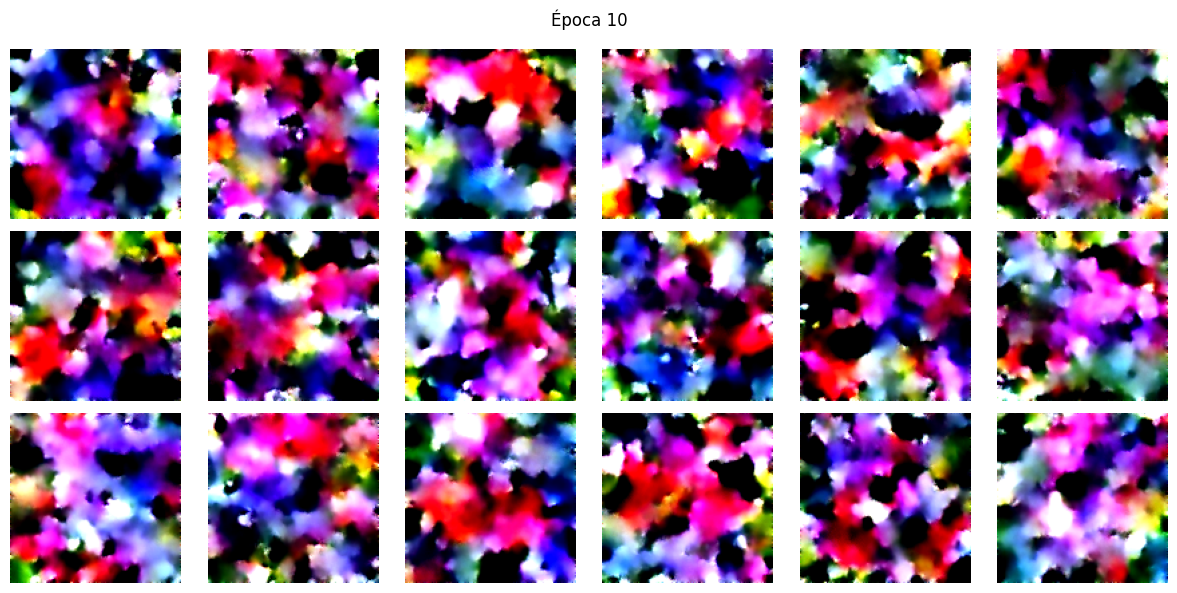

255/255 ━━━━━━━━━━━━━━━━━━━━ 1279s 5s/step - loss: 0.1657
Epoch 11/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1202s 5s/step - loss: 0.1649
Epoch 12/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1172s 5s/step - loss: 0.1617
Epoch 13/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1192s 5s/step - loss: 0.1588
Epoch 14/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1170s 5s/step - loss: 0.1598
Epoch 15/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1168s 5s/step - loss: 0.1582
Epoch 16/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1366s 5s/step - loss: 0.1558
Epoch 17/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1428s 6s/step - loss: 0.1553
Epoch 18/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1107s 4s/step - loss: 0.1541
Epoch 19/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1174s 4s/step - loss: 0.1525
Epoch 20/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - loss: 0.1523

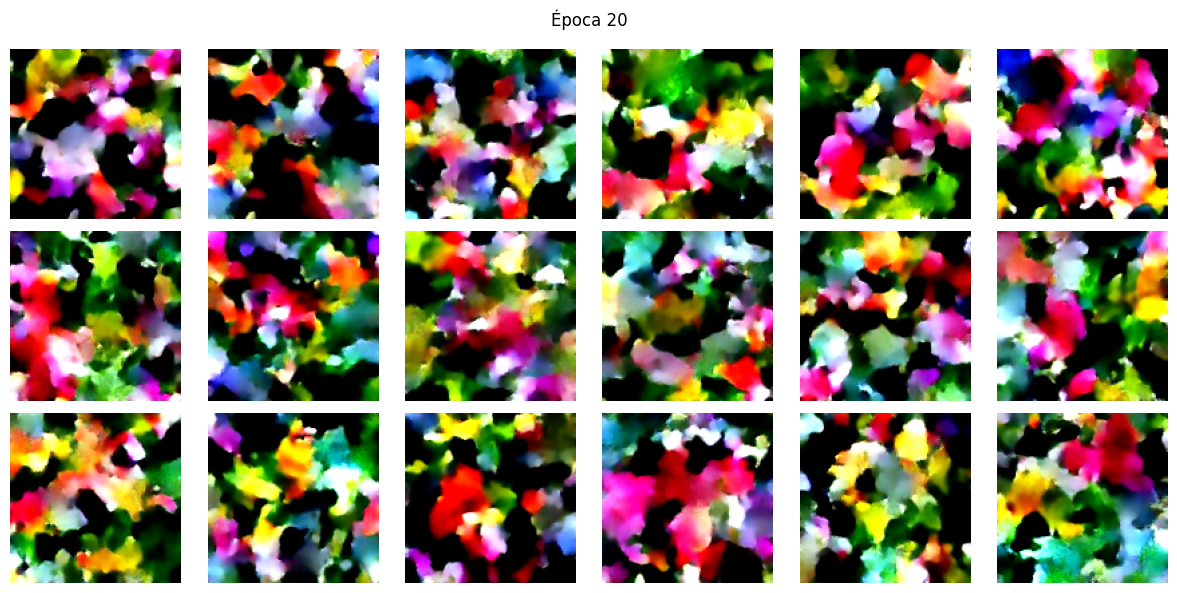

255/255 ━━━━━━━━━━━━━━━━━━━━ 1132s 4s/step - loss: 0.1519
Epoch 21/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1109s 4s/step - loss: 0.1510
Epoch 22/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1103s 4s/step - loss: 0.1511
Epoch 23/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1116s 4s/step - loss: 0.1503
Epoch 24/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1117s 4s/step - loss: 0.1490
Epoch 25/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1137s 4s/step - loss: 0.1488
Epoch 26/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1138s 4s/step - loss: 0.1460
Epoch 27/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1156s 5s/step - loss: 0.1464
Epoch 28/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1165s 5s/step - loss: 0.1475
Epoch 29/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1156s 5s/step - loss: 0.1445
Epoch 30/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - loss: 0.1462

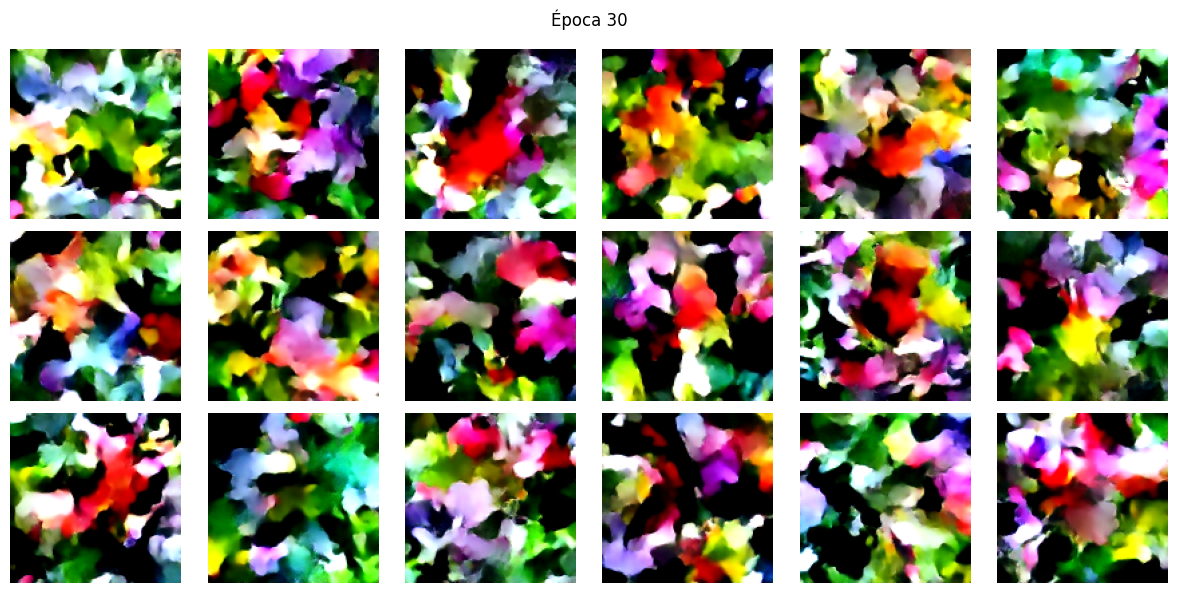

255/255 ━━━━━━━━━━━━━━━━━━━━ 1115s 4s/step - loss: 0.1452
Epoch 31/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1114s 4s/step - loss: 0.1446
Epoch 32/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1107s 4s/step - loss: 0.1450
Epoch 33/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1115s 4s/step - loss: 0.1439
Epoch 34/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1119s 4s/step - loss: 0.1433
Epoch 35/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1103s 4s/step - loss: 0.1434
Epoch 36/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1103s 4s/step - loss: 0.1428
Epoch 37/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1116s 4s/step - loss: 0.1419
Epoch 38/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1143s 4s/step - loss: 0.1427
Epoch 39/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1096s 4s/step - loss: 0.1425
Epoch 40/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - loss: 0.1425

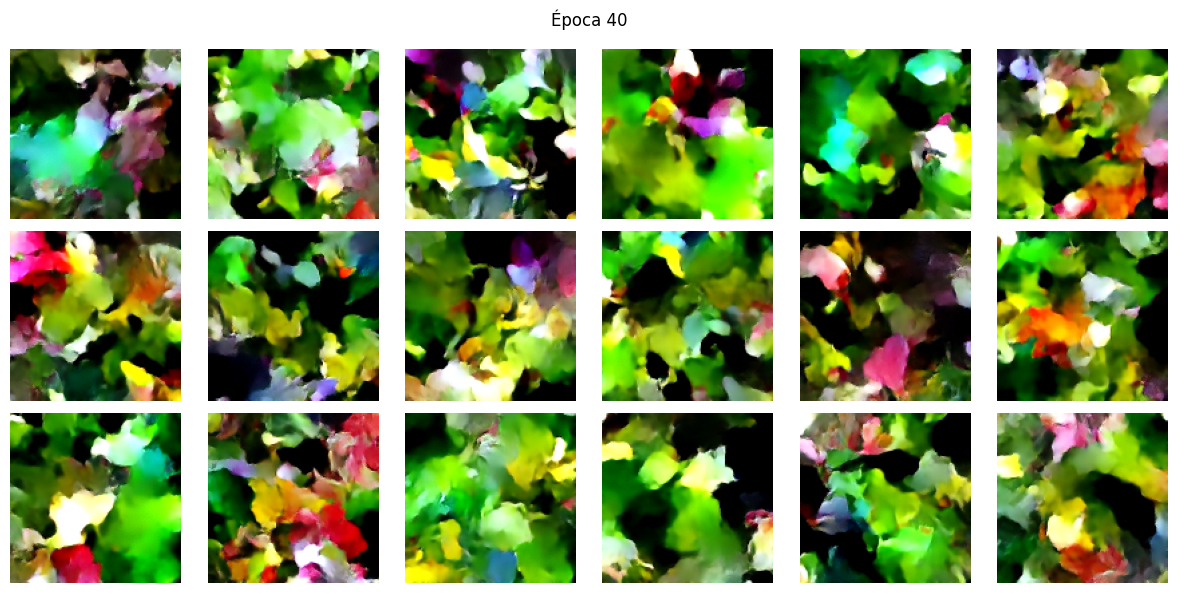

255/255 ━━━━━━━━━━━━━━━━━━━━ 1140s 4s/step - loss: 0.1414
Epoch 41/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1140s 4s/step - loss: 0.1409
Epoch 42/100
255/255 ━━━━━━━━━━━━━━━━━━━━ 1106s 4s/step - loss: 0.1424
Epoch 43/100
179/255 ━━━━━━━━━━━━━━━━━━━━ 6:02 5s/step - loss: 0.1448

KeyboardInterrupt: 

In [14]:
EPOCHS = 100   # como en el libro. Si tienes poco tiempo de GPU, 50 ya da flores reconocibles.

t0 = time.time()
history = model.fit(
    dataset,
    epochs=EPOCHS,
    callbacks=[
        VisualizationCallback(every=10),
        keras.callbacks.ModelCheckpoint(
            filepath="diffusion_model.weights.h5",
            save_weights_only=True,
            save_best_only=True,
            monitor="loss",          # no hay conjunto de validación: vigilamos la pérdida de entrenamiento
        ),
    ],
)
print(f"Tiempo de entrenamiento: {(time.time() - t0) / 60:.1f} min")

In [ ]:
plt.figure(figsize=(6, 3))
plt.plot(history.history["loss"])
plt.xlabel("época"); plt.ylabel("MAE del ruido"); plt.grid(True)
plt.title("Curva de aprendizaje"); plt.show()

## 6. Generación de flores nuevas

In [ ]:
def show_images(images, n_cols=6, size=2.0, title=None, titles=None):
    images = ops.convert_to_numpy(images).astype("uint8")
    n_rows = (len(images) - 1) // n_cols + 1
    plt.figure(figsize=(n_cols * size, n_rows * size))
    for i, img in enumerate(images):
        plt.subplot(n_rows, n_cols, i + 1); plt.imshow(img); plt.axis("off")
        if titles is not None:
            plt.title(titles[i], fontsize=9)
    if title:
        plt.suptitle(title)
    plt.tight_layout(); plt.show()

generated = model.generate(num_images=24, diffusion_steps=20)
show_images(generated, n_cols=8, title="Flores generadas (20 pasos de difusión)")

## 7. Experimentos adicionales para entender el modelo
### 7.1 Efecto del número de pasos de difusión
Como el muestreo es determinista dado el ruido inicial, podemos fijar el **mismo ruido** y variar solo el número de pasos. Con muy pocos pasos la imagen sale borrosa (el modelo tiene que “adivinar” todo de una vez); a partir de ~20 pasos la mejora es marginal.

In [ ]:
def generate_from_noise(initial_noise, diffusion_steps, return_trajectory=False):
    # Igual que model.generate, pero partiendo de un ruido dado y (opcional) guardando cada paso
    noisy_images = initial_noise
    num_images = initial_noise.shape[0]
    step_size = 1.0 / diffusion_steps
    traj_noisy, traj_pred = [], []
    for step in range(diffusion_steps):
        diffusion_times = ops.ones((num_images, 1, 1, 1)) - step * step_size
        noise_rates, signal_rates = diffusion_schedule(diffusion_times)
        pred_images, pred_noises = model.denoise(noisy_images, noise_rates, signal_rates)
        if return_trajectory:
            traj_noisy.append(ops.convert_to_numpy(noisy_images))
            traj_pred.append(ops.convert_to_numpy(pred_images))
        next_noise_rates, next_signal_rates = diffusion_schedule(diffusion_times - step_size)
        noisy_images = next_signal_rates * pred_images + next_noise_rates * pred_noises
    denorm = lambda x: np.clip(ops.convert_to_numpy(model.normalizer.mean)
                               + x * ops.convert_to_numpy(model.normalizer.variance) ** 0.5, 0, 255)
    images = denorm(ops.convert_to_numpy(pred_images))
    if return_trajectory:
        return images, [denorm(x) for x in traj_noisy], [denorm(x) for x in traj_pred]
    return images

fixed_noise = keras.random.normal((4, image_size, image_size, 3), seed=7)
steps_list = [1, 2, 5, 10, 20, 50]
cols = []
for s in steps_list:
    cols.append(generate_from_noise(fixed_noise, s))
grid = np.stack(cols, axis=1).reshape(-1, image_size, image_size, 3)   # filas = semillas, columnas = pasos
show_images(grid, n_cols=len(steps_list), size=1.8,
            titles=[f"{s} pasos" for s in steps_list] + [""] * (len(grid) - len(steps_list)),
            title="Mismo ruido inicial, distinto número de pasos")

### 7.2 El proceso inverso paso a paso
Para una misma flor mostramos, en cada paso, la **imagen ruidosa** que entra al modelo (arriba) y la **imagen limpia que el modelo predice** en ese momento (abajo). Se ve cómo primero se decide la composición y los colores, y luego se afinan pétalos y bordes.

In [ ]:
STEPS = 20
_, traj_noisy, traj_pred = generate_from_noise(fixed_noise[:1], STEPS, return_trajectory=True)
show_idx = [0, 2, 4, 6, 8, 11, 14, 17, 19]
row1 = [traj_noisy[i][0] for i in show_idx]
row2 = [traj_pred[i][0] for i in show_idx]
show_images(np.array(row1 + row2), n_cols=len(show_idx), size=1.6,
            titles=[f"paso {i + 1}" for i in show_idx] + [""] * len(show_idx),
            title="Arriba: entrada ruidosa x_t · Abajo: imagen limpia predicha x̂₀")

### 7.3 Interpolación en el espacio de ruido
El ruido inicial funciona como un “código latente”: si interpolamos esféricamente (*slerp*) entre dos ruidos, las flores generadas cambian suavemente de una a otra. Eso muestra que el modelo aprendió un espacio continuo y no está memorizando imágenes sueltas.

In [ ]:
def slerp(t, v1, v2):
    v1n, v2n = v1 / np.linalg.norm(v1), v2 / np.linalg.norm(v2)
    omega = np.arccos(np.clip((v1n * v2n).sum(), -1, 1))
    return (np.sin((1 - t) * omega) * v1 + np.sin(t * omega) * v2) / np.sin(omega)

z = ops.convert_to_numpy(keras.random.normal((2, image_size, image_size, 3), seed=21))
interp = np.stack([slerp(t, z[0], z[1]) for t in np.linspace(0, 1, 8)]).astype("float32")
show_images(generate_from_noise(ops.convert_to_tensor(interp), 20), n_cols=8, size=1.8,
            title="Interpolación esférica entre dos ruidos iniciales")

### 7.4 Evaluación cuantitativa: KID
El *Kernel Inception Distance* compara las características de InceptionV3 de imágenes reales y generadas (MMD² con kernel polinomial). Es la métrica que usa el ejemplo oficial de Keras de DDIM sobre este mismo dataset y, a diferencia del FID, es insesgada con pocas muestras. **Más bajo es mejor.** Como referencia calculamos también el KID entre dos grupos de imágenes reales (el “piso”) y entre ruido y reales (el “techo”).

In [ ]:
N_KID = 500
inception = keras.applications.InceptionV3(include_top=False, pooling="avg",
                                           weights="imagenet", input_shape=(299, 299, 3))

def inception_features(images_0_255, bs=25):
    feats = []
    for i in range(0, len(images_0_255), bs):
        x = ops.image.resize(ops.convert_to_tensor(images_0_255[i:i + bs], dtype="float32"), (299, 299))
        x = keras.applications.inception_v3.preprocess_input(x)
        feats.append(ops.convert_to_numpy(inception(x, training=False)))
    return np.concatenate(feats).astype(np.float64)

def kid(f1, f2):
    d, m = f1.shape[1], min(len(f1), len(f2))
    f1, f2 = f1[:m], f2[:m]
    kxx, kyy, kxy = (f1 @ f1.T / d + 1) ** 3, (f2 @ f2.T / d + 1) ** 3, (f1 @ f2.T / d + 1) ** 3
    return float((kxx.sum() - np.trace(kxx)) / (m * (m - 1))
                 + (kyy.sum() - np.trace(kyy)) / (m * (m - 1)) - 2 * kxy.mean())

real = np.concatenate([b.numpy() for b in dataset.take(2 * N_KID // batch_size + 1)])[: 2 * N_KID]
chunks = [100] * (N_KID // 100) + ([N_KID % 100] if N_KID % 100 else [])
gen = np.concatenate([ops.convert_to_numpy(model.generate(c, 20)) for c in chunks])
noise_imgs = np.random.uniform(0, 255, gen.shape).astype("float32")

f_real_a, f_real_b = inception_features(real[:N_KID]), inception_features(real[N_KID:])
f_gen, f_noise = inception_features(gen), inception_features(noise_imgs)

print(f"KID real vs real (piso) : {kid(f_real_a, f_real_b):.4f}")
print(f"KID generadas vs reales : {kid(f_gen, f_real_a):.4f}")
print(f"KID ruido vs reales     : {kid(f_noise, f_real_a):.4f}")

## 8. Conclusiones

- El modelo del libro logra flores de 128×128 bastante convincentes con una U-Net pequeña (~1,9 M de parámetros, unas 7 veces la del notebook de clase), gracias a tres decisiones: **tiempo continuo con programación coseno**, **muestreo DDIM determinista** (20 pasos bastan) y **EMA de los pesos**.
- Los experimentos muestran el carácter **de grueso a fino** de la difusión: en los primeros pasos se fijan composición y color; en los últimos, texturas y bordes.
- La interpolación suave en el espacio de ruido evidencia que el modelo aprendió una representación continua de “flor”.
- Limitaciones típicas: algunas flores salen con formas ambiguas o fondos poco coherentes; con más épocas, más anchura en la U-Net o capas de atención la calidad mejora.

> 📝 Completa esta sección con tus resultados (KID obtenido, tiempo de entrenamiento y observaciones de las imágenes).

In [ ]:
model.save_weights("flowers_diffusion_final.weights.h5")
print("Pesos guardados en flowers_diffusion_final.weights.h5")